## Device

In [1]:
import torch
import gc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM total:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM total: 6.05 GB


## Dataset dan transform

In [2]:
import os
from torchvision import datasets, transforms

DATA_DIR = 'archive'
IMG_SIZE = 384
RESIZE_SIZE = 420

full_dataset = datasets.ImageFolder(DATA_DIR)
class_names = full_dataset.classes
NUM_CLASSES = len(class_names)
print(f"{NUM_CLASSES} kelas dengan {len(full_dataset)} gambar.")

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((RESIZE_SIZE, RESIZE_SIZE)),
        transforms.RandomCrop(IMG_SIZE),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(7),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((RESIZE_SIZE, RESIZE_SIZE)),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

45 kelas dengan 14376 gambar.


## Persebaran kelas dataset

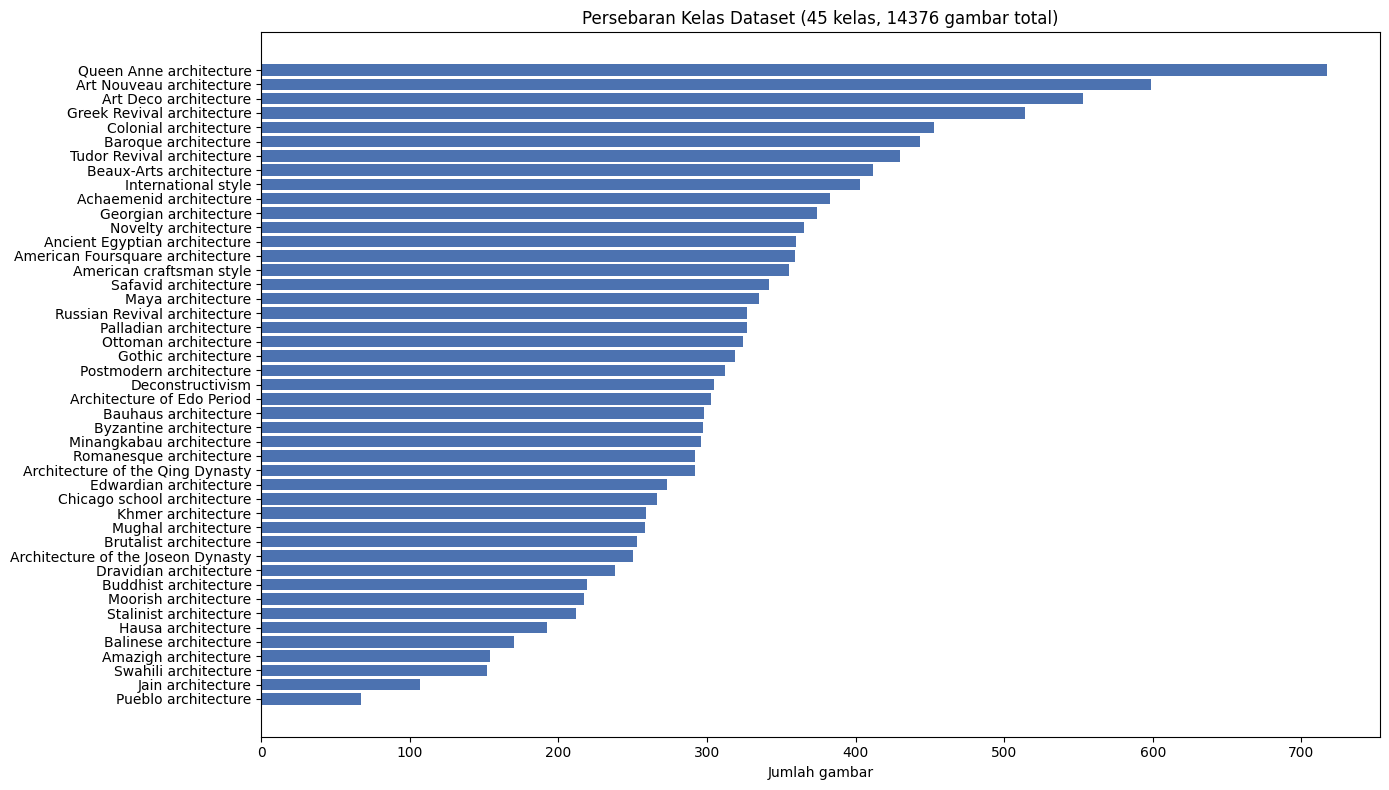

Jumlah gambar per kelas, min 67, max 717, mean 319.5


In [3]:
import matplotlib.pyplot as plt
import numpy as np

class_counts = np.bincount(full_dataset.targets, minlength=NUM_CLASSES)
order = np.argsort(class_counts)[::-1]

plt.figure(figsize=(14, 8))
plt.barh([class_names[i] for i in order][::-1], [class_counts[i] for i in order][::-1], color='#4C72B0')
plt.xlabel('Jumlah gambar')
plt.title(f'Persebaran Kelas Dataset ({NUM_CLASSES} kelas, {len(full_dataset)} gambar total)')
plt.tight_layout()
plt.show()

print(f"Jumlah gambar per kelas, min {class_counts.min()}, max {class_counts.max()}, mean {class_counts.mean():.1f}")

CutMix/MixUp

In [4]:
import torch
from torch.utils.data import Dataset
from torchvision.transforms import v2

class MapDataset(Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform
    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]
        if self.transform: x = self.transform(x)
        return x, y
    def __len__(self): return len(self.indices)

cutmix = v2.CutMix(num_classes=NUM_CLASSES)
mixup = v2.MixUp(num_classes=NUM_CLASSES)
cutmix_or_mixup = v2.RandomChoice([cutmix, mixup])
CUTMIX_MIXUP_PROB = 0.5

def cutmix_mixup_collate_fn(batch):
    inputs, labels = torch.utils.data.default_collate(batch)
    if torch.rand(1).item() < CUTMIX_MIXUP_PROB:
        return cutmix_or_mixup(inputs, labels)
    return inputs, labels

## Stratified split (test 10%, held-out) + 5-fold CV di sisa pool

In [5]:
import json
import time
import numpy as np
from sklearn.model_selection import StratifiedKFold, train_test_split

TEST_FRAC = 0.10
N_FOLDS = 5
RANDOM_STATE = 42
CHECKPOINT_DIR = 'checkpoint_densenet121'
RUN_ID = 'densenet121'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

all_filepaths = np.array([p for p, _ in full_dataset.samples])
all_targets = np.array(full_dataset.targets)
all_idx = np.arange(len(full_dataset.samples))

pool_idx, test_idx = train_test_split(
    all_idx, test_size=TEST_FRAC, stratify=all_targets, random_state=RANDOM_STATE
)

print(f"Pool untuk CV: {len(pool_idx)} gambar | Held-out test: {len(test_idx)} gambar")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
fold_splits_local = list(skf.split(pool_idx, all_targets[pool_idx]))
fold_splits = [(pool_idx[tr], pool_idx[va]) for tr, va in fold_splits_local]

fold_export = []
for i, (train_idx, val_idx) in enumerate(fold_splits):
    fold_export.append({
        'fold': i + 1,
        'val_filepaths': [full_dataset.samples[j][0] for j in val_idx],
        'val_labels': [full_dataset.samples[j][1] for j in val_idx],
    })

RUN_TIMESTAMP = time.strftime('%Y%m%d_%H%M%S')
fold_split_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_splits_{RUN_TIMESTAMP}.json')
with open(fold_split_path, 'w') as f:
    json.dump({
        'class_names': class_names,
        'folds': fold_export,
        'held_out_test_filepaths': [full_dataset.samples[j][0] for j in test_idx],
    }, f)
print(f"Pembagian {N_FOLDS} fold (held-out test terpisah) diekspor ke {fold_split_path}")

Pool untuk CV: 12938 gambar | Held-out test: 1438 gambar
Pembagian 5 fold (held-out test terpisah) diekspor ke checkpoint_densenet121/densenet121_fold_splits_20261012_105952.json


## Jumlah data gambar (train, val, test)

In [6]:
print(f"Total gambar keseluruhan : {len(full_dataset)}")
print(f"Held-out test            : {len(test_idx)} gambar ({len(test_idx)/len(full_dataset)*100:.1f}%)")
print(f"Pool untuk CV (train+val) : {len(pool_idx)} gambar ({len(pool_idx)/len(full_dataset)*100:.1f}%)")
print()
for i, (train_idx_i, val_idx_i) in enumerate(fold_splits):
    print(f"Fold {i + 1}: train = {len(train_idx_i)} gambar | val = {len(val_idx_i)} gambar")

Total gambar keseluruhan : 14376
Held-out test            : 1438 gambar (10.0%)
Pool untuk CV (train+val) : 12938 gambar (90.0%)

Fold 1: train = 10350 gambar | val = 2588 gambar
Fold 2: train = 10350 gambar | val = 2588 gambar
Fold 3: train = 10350 gambar | val = 2588 gambar
Fold 4: train = 10351 gambar | val = 2587 gambar
Fold 5: train = 10351 gambar | val = 2587 gambar


## Fungsi satu epoch

In [7]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))

def run_epoch(model, loader, size, optimizer=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()

    running_loss = 0.0
    running_correct = 0

    with torch.set_grad_enabled(train_mode):
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if train_mode:
                optimizer.zero_grad()

            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            preds = outputs.argmax(1)

            if train_mode:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            running_loss += loss.item() * inputs.size(0)
            hard_labels = labels.argmax(1) if labels.ndim == 2 else labels
            running_correct += (preds == hard_labels).sum().item()

    return running_loss / size, running_correct / size

## TRANSFER LEARNING: FEATURE EXTRACTION

In [8]:
import copy
import torch.nn as nn
import torch.optim as optim
from torchvision import models

def build_feature_extraction_model():
    weights = models.DenseNet121_Weights.IMAGENET1K_V1
    model = models.densenet121(weights=weights)

    for param in model.parameters():
        param.requires_grad = False


    model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)
    for param in model.classifier.parameters():
        param.requires_grad = True

    model = model.to(device)


    original_train = model.train
    def train_frozen_backbone(mode=True):
        original_train(mode)
        if mode:
            for module in model.features.modules():
                if isinstance(module, nn.BatchNorm2d):
                    module.eval()
        return model
    model.train = train_frozen_backbone

    return model

def train_feature_extraction(model, dataloaders, dataset_sizes, epochs=100,
                              lr=1e-4, weight_decay=1e-4, verbose_prefix="",
                              ckpt_path=None, validate=True):
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(trainable_params, lr=lr, weight_decay=weight_decay)

    history = {'train_loss': [], 'train_acc': []}
    if validate:
        history['val_loss'] = []
        history['val_acc'] = []
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    start_epoch = 0

    if ckpt_path is not None and os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        scaler.load_state_dict(ckpt['scaler_state'])
        history = ckpt['history']
        best_acc = ckpt['best_acc']
        best_model_wts = ckpt['best_model_wts']
        start_epoch = ckpt['epoch'] + 1
        torch.set_rng_state(ckpt['rng_state'].cpu())
        if device.type == "cuda" and ckpt.get('cuda_rng_state') is not None:
            torch.cuda.set_rng_state(ckpt['cuda_rng_state'].cpu())
        print(f"{verbose_prefix}Melanjutkan dari checkpoint: epoch {start_epoch + 1}/{epochs} "
              f"(best_acc sejauh ini {best_acc:.4f})")

    if start_epoch >= epochs:
        print(f"{verbose_prefix}Checkpoint sudah menyelesaikan {epochs} epoch, training dilewati.")
        model.load_state_dict(best_model_wts)
        del optimizer
        return model, history, best_acc

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = run_epoch(model, dataloaders['train'], dataset_sizes['train'], optimizer)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)

        if validate:
            val_loss, val_acc = run_epoch(model, dataloaders['val'], dataset_sizes['val'])
            history['val_loss'].append(val_loss)
            history['val_acc'].append(val_acc)
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f} "
                  f"| val_loss {val_loss:.4f} acc {val_acc:.4f}")
            if val_acc > best_acc:
                best_acc = val_acc
                best_model_wts = copy.deepcopy(model.state_dict())
        else:
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f}")
            best_acc = train_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        if ckpt_path is not None:
            tmp_path = ckpt_path + '.tmp'
            torch.save({
                'epoch': epoch,
                'model_state': model.state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'scaler_state': scaler.state_dict(),
                'history': history,
                'best_acc': best_acc,
                'best_model_wts': best_model_wts,
                'rng_state': torch.get_rng_state(),
                'cuda_rng_state': torch.cuda.get_rng_state() if device.type == "cuda" else None,
            }, tmp_path)
            os.replace(tmp_path, ckpt_path)

    model.load_state_dict(best_model_wts)
    del optimizer
    torch.cuda.empty_cache()
    gc.collect()
    return model, history, best_acc

## Loop 5 fold (feature extraction)

In [9]:
import numpy as np
from torch.utils.data import DataLoader

BATCH_SIZE = 74
NUM_WORKERS = os.cpu_count()
EPOCHS = 300

FOLD_RESULTS_PATH = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_results.pt')

if os.path.exists(FOLD_RESULTS_PATH):
    fold_results = torch.load(FOLD_RESULTS_PATH, weights_only=False)
    done_folds = {r['fold'] for r in fold_results}
    print(f"Melanjutkan run sebelumnya: fold {sorted(done_folds)} sudah selesai, dilewati.")
else:
    fold_results = []
    done_folds = set()

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits):
    fold_num = fold_idx + 1
    if fold_num in done_folds:
        continue

    print(f"\n FOLD {fold_num}/{N_FOLDS} (DenseNet121)")

    train_dataset = MapDataset(full_dataset, train_idx, transform=data_transforms['train'])
    val_dataset = MapDataset(full_dataset, val_idx, transform=data_transforms['val'])
    dataloaders = {
        'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                             pin_memory=True, collate_fn=cutmix_mixup_collate_fn),
        'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    }
    dataset_sizes = {'train': len(train_dataset), 'val': len(val_dataset)}

    model = build_feature_extraction_model()
    epoch_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_num}_epochckpt.pth')
    model, history, best_acc = train_feature_extraction(
        model, dataloaders, dataset_sizes, epochs=EPOCHS, verbose_prefix=f"  [DenseNet121] ",
        ckpt_path=epoch_ckpt_path
    )

    torch.cuda.empty_cache()
    gc.collect()

    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_num}.pth')
    torch.save(model.state_dict(), ckpt_path)
    print(f"Bobot fold {fold_num} disimpan di {ckpt_path}")

    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in dataloaders['val']:
            outputs = model(inputs.to(device))
            preds = outputs.argmax(1).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(preds)

    fold_results.append({
        'fold': fold_num,
        'best_val_acc': best_acc,
        'history': history,
        'y_true': np.array(y_true),
        'y_pred': np.array(y_pred),
    })
    torch.save(fold_results, FOLD_RESULTS_PATH)

    if os.path.exists(epoch_ckpt_path):
        os.remove(epoch_ckpt_path)

    del model, dataloaders, train_dataset, val_dataset
    torch.cuda.empty_cache()
    gc.collect()


 FOLD 1/5 (DenseNet121)
  [DenseNet121] Melanjutkan dari checkpoint: epoch 284/300 (best_acc sejauh ini 0.6886)
  [DenseNet121] Epoch 284/300 | train_loss 1.9184 acc 0.6952 | val_loss 1.6661 acc 0.6832
  [DenseNet121] Epoch 285/300 | train_loss 1.9503 acc 0.6895 | val_loss 1.6667 acc 0.6839
  [DenseNet121] Epoch 286/300 | train_loss 1.9771 acc 0.6631 | val_loss 1.6651 acc 0.6824
  [DenseNet121] Epoch 287/300 | train_loss 1.9514 acc 0.6842 | val_loss 1.6652 acc 0.6855
  [DenseNet121] Epoch 288/300 | train_loss 1.8834 acc 0.6986 | val_loss 1.6653 acc 0.6855
  [DenseNet121] Epoch 289/300 | train_loss 1.9507 acc 0.6814 | val_loss 1.6651 acc 0.6855
  [DenseNet121] Epoch 290/300 | train_loss 1.9512 acc 0.6808 | val_loss 1.6629 acc 0.6851
  [DenseNet121] Epoch 291/300 | train_loss 1.9165 acc 0.6996 | val_loss 1.6647 acc 0.6847
  [DenseNet121] Epoch 292/300 | train_loss 1.8357 acc 0.7158 | val_loss 1.6665 acc 0.6824
  [DenseNet121] Epoch 293/300 | train_loss 1.8016 acc 0.7232 | val_loss 1.664

## Ringkasan akurasi antar fold

Akurasi validasi per fold: [0.6901, 0.7021, 0.6886, 0.6881, 0.6881]
Rata rata: 0.6914   Std: 0.0054


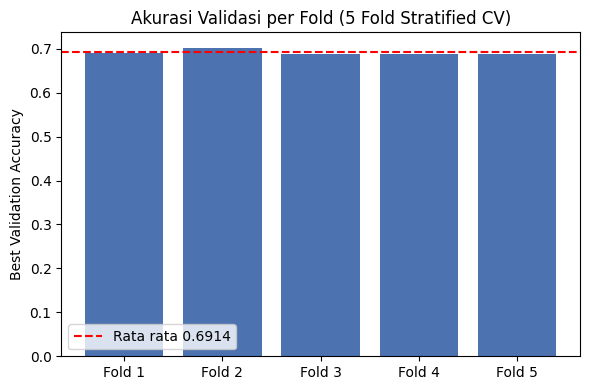

In [10]:
import matplotlib.pyplot as plt

accs = [r['best_val_acc'] for r in fold_results]
print(f"Akurasi validasi per fold: {[round(a, 4) for a in accs]}")
print(f"Rata rata: {np.mean(accs):.4f}   Std: {np.std(accs):.4f}")

plt.figure(figsize=(6, 4))
plt.bar([f"Fold {r['fold']}" for r in fold_results], accs, color='#4C72B0')
plt.axhline(np.mean(accs), color='red', linestyle='--', label=f"Rata rata {np.mean(accs):.4f}")
plt.ylabel('Best Validation Accuracy')
plt.title('Akurasi Validasi per Fold (5 Fold Stratified CV)')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

per_fold_metrics = []
for r in fold_results:
    y_true_f = r['y_true']
    y_pred_f = r['y_pred']
    per_fold_metrics.append({
        'fold': r['fold'],
        'accuracy': r['best_val_acc'],
        'precision_macro': precision_score(y_true_f, y_pred_f, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true_f, y_pred_f, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true_f, y_pred_f, average='macro', zero_division=0),
    })

for m in per_fold_metrics:
    print(f"Fold {m['fold']}: acc {m['accuracy']:.4f}  precision {m['precision_macro']:.4f}  "
          f"recall {m['recall_macro']:.4f}  f1 {m['f1_macro']:.4f}")

import pandas as pd
df_fold_metrics = pd.DataFrame(per_fold_metrics)
df_fold_metrics.to_csv(os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_metrics_{RUN_TIMESTAMP}.csv'), index=False)
df_fold_metrics

Fold 1: acc 0.6901  precision 0.7175  recall 0.6884  f1 0.6930
Fold 2: acc 0.7021  precision 0.7279  recall 0.7061  f1 0.7107
Fold 3: acc 0.6886  precision 0.7033  recall 0.6899  f1 0.6931
Fold 4: acc 0.6881  precision 0.7039  recall 0.6889  f1 0.6891
Fold 5: acc 0.6881  precision 0.7123  recall 0.6899  f1 0.6935


,fold,accuracy,precision_macro,recall_macro,f1_macro
0,1,0.690108,0.717550,0.688436,0.693003
1,2,0.702087,0.727936,0.706104,0.710748
2,3,0.688563,0.703260,0.689950,0.693096
3,4,0.688056,0.703882,0.688873,0.689140
4,5,0.688056,0.712348,0.689883,0.693513


## Classification report dan confusion matrix


Model Evaluation Report gabungan 5 fold (Classification Report):

                                    precision    recall  f1-score   support

           Achaemenid architecture     0.8925    0.8667    0.8794       345
              Amazigh architecture     0.8571    0.6906    0.7649       139
  American Foursquare architecture     0.6016    0.6966    0.6456       323
          American craftsman style     0.5710    0.5925    0.5815       319
     Ancient Egyptian architecture     0.9609    0.9105    0.9350       324
        Architecture of Edo Period     0.8415    0.8755    0.8582       273
Architecture of the Joseon Dynasty     0.8486    0.8222    0.8352       225
  Architecture of the Qing Dynasty     0.8889    0.8213    0.8538       263
             Art Deco architecture     0.6061    0.5964    0.6012       498
          Art Nouveau architecture     0.6909    0.6512    0.6705       539
             Balinese architecture     0.8760    0.7386    0.8014       153
              Baroqu

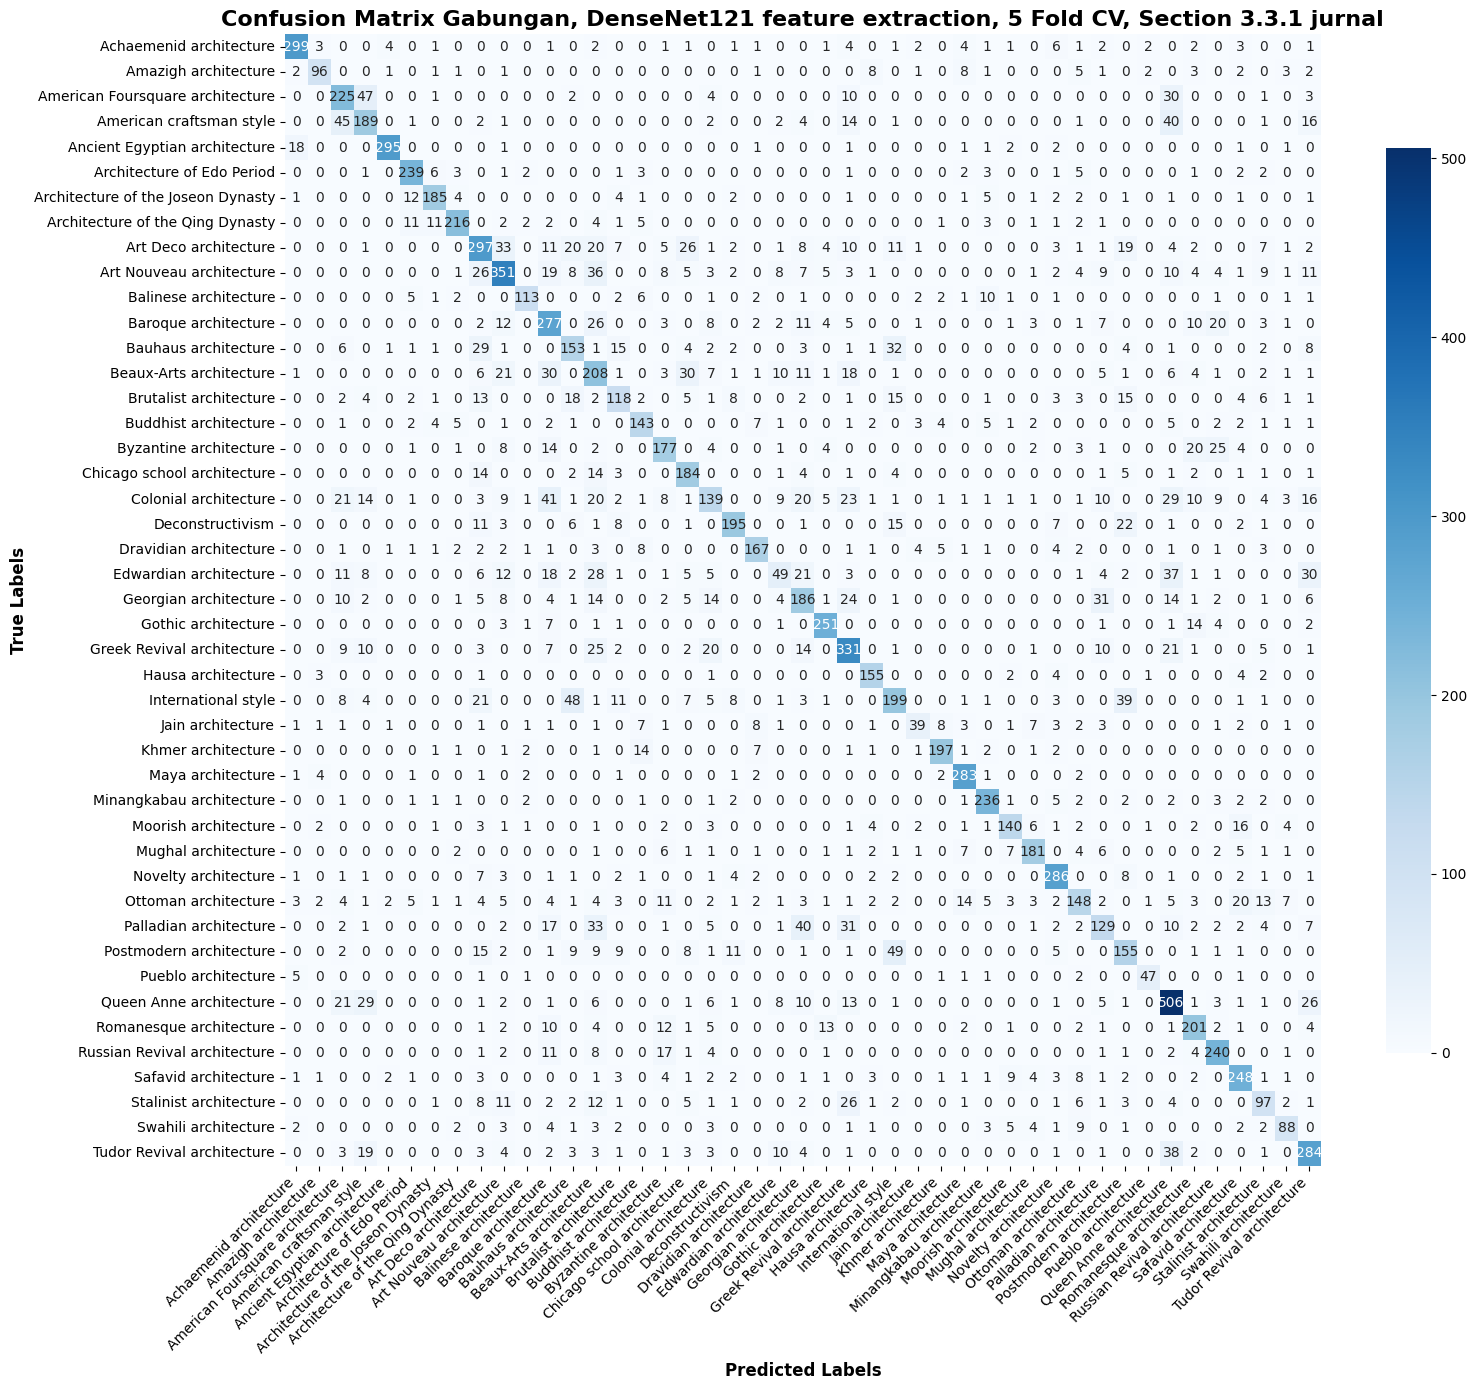

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true_all = np.concatenate([r['y_true'] for r in fold_results])
y_pred_all = np.concatenate([r['y_pred'] for r in fold_results])

print("\nModel Evaluation Report gabungan 5 fold (Classification Report):\n")
print(classification_report(y_true_all, y_pred_all, target_names=class_names, digits=4))

cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'shrink': 0.8})
plt.xlabel('Predicted Labels', fontsize=12, fontweight='bold')
plt.ylabel('True Labels', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix Gabungan, DenseNet121 feature extraction, 5 Fold CV, Section 3.3.1 jurnal', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Retrain model final (feature extraction)

In [13]:
best_epochs_per_fold = []
for r in fold_results:
    val_accs = r['history']['val_acc']
    best_epoch = int(np.argmax(val_accs)) + 1
    best_epochs_per_fold.append(best_epoch)

FINAL_EPOCHS = int(round(np.mean(best_epochs_per_fold)))
print(f"Epoch terbaik per fold: {best_epochs_per_fold}")
print(f"Rata rata epoch terbaik (dipakai untuk retrain final): {FINAL_EPOCHS}")

Epoch terbaik per fold: [300, 293, 297, 293, 299]
Rata rata epoch terbaik (dipakai untuk retrain final): 296


In [14]:
from torch.utils.data import DataLoader

final_train_dataset = MapDataset(full_dataset, pool_idx, transform=data_transforms['train'])
final_dataloaders = {
    'train': DataLoader(final_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                         pin_memory=True, collate_fn=cutmix_mixup_collate_fn),
}
final_dataset_sizes = {'train': len(final_train_dataset)}
print(f"Data training final: {final_dataset_sizes['train']} gambar (100% training pool, tanpa val split, test_idx tidak disentuh)")

final_model = build_feature_extraction_model()
final_epoch_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final_epochckpt.pth')
final_model, final_history, _ = train_feature_extraction(
    final_model, final_dataloaders, final_dataset_sizes, epochs=FINAL_EPOCHS, verbose_prefix="  [FINAL] ",
    ckpt_path=final_epoch_ckpt_path, validate=False
)

torch.cuda.empty_cache()
gc.collect()

final_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth')
torch.save(final_model.state_dict(), final_ckpt_path)
print(f"Model final disimpan di {final_ckpt_path}")

if os.path.exists(final_epoch_ckpt_path):
    os.remove(final_epoch_ckpt_path)

Data training final: 12938 gambar (100% training pool, tanpa val split, test_idx tidak disentuh)
  [FINAL] Epoch 1/296 | train_loss 3.6867 acc 0.0630
  [FINAL] Epoch 2/296 | train_loss 3.4581 acc 0.1737
  [FINAL] Epoch 3/296 | train_loss 3.2812 acc 0.2500
  [FINAL] Epoch 4/296 | train_loss 3.1382 acc 0.3059
  [FINAL] Epoch 5/296 | train_loss 3.0155 acc 0.3514
  [FINAL] Epoch 6/296 | train_loss 2.9150 acc 0.3847
  [FINAL] Epoch 7/296 | train_loss 2.8491 acc 0.4088
  [FINAL] Epoch 8/296 | train_loss 2.7738 acc 0.4150
  [FINAL] Epoch 9/296 | train_loss 2.7238 acc 0.4358
  [FINAL] Epoch 10/296 | train_loss 2.6745 acc 0.4492
  [FINAL] Epoch 11/296 | train_loss 2.6184 acc 0.4756
  [FINAL] Epoch 12/296 | train_loss 2.5362 acc 0.4895
  [FINAL] Epoch 13/296 | train_loss 2.5897 acc 0.4682
  [FINAL] Epoch 14/296 | train_loss 2.5316 acc 0.4971
  [FINAL] Epoch 15/296 | train_loss 2.4685 acc 0.5130
  [FINAL] Epoch 16/296 | train_loss 2.4348 acc 0.5168
  [FINAL] Epoch 17/296 | train_loss 2.4186 acc 0

## Load model tersimpan tanpa retrain

In [9]:
import glob
import json
import numpy as np
import os

CHECKPOINT_DIR = 'checkpoint_densenet121'
RUN_ID = 'densenet121'

candidate_paths = sorted(glob.glob(os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_splits_*.json')))
assert candidate_paths, f"Tidak ada file fold_splits di {CHECKPOINT_DIR}"
EVAL_FOLD_SPLIT_PATH = candidate_paths[-1]
print(f"Memuat pembagian fold dari {EVAL_FOLD_SPLIT_PATH}")

with open(EVAL_FOLD_SPLIT_PATH) as f:
    saved_splits = json.load(f)

class_names = saved_splits['class_names']
NUM_CLASSES = len(class_names)

filepath_to_idx = {path: i for i, (path, _) in enumerate(full_dataset.samples)}
loaded_val_indices = []
for fold in saved_splits['folds']:
    val_idx = np.array([filepath_to_idx[p] for p in fold['val_filepaths']])
    loaded_val_indices.append(val_idx)

N_FOLDS = len(loaded_val_indices)
print(f"Jumlah fold termuat: {N_FOLDS}")

test_idx = np.array([filepath_to_idx[p] for p in saved_splits['held_out_test_filepaths']])
print(f"Held-out test set termuat: {len(test_idx)} gambar")

Memuat pembagian fold dari checkpoint_densenet121/densenet121_fold_splits_20261012_105952.json
Jumlah fold termuat: 5
Held-out test set termuat: 1438 gambar


In [10]:
import gc
import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

BATCH_SIZE = 74
NUM_WORKERS = os.cpu_count()

def build_model_for_load():
    model = models.densenet121(weights=None)
    model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)
    return model.to(device)

def load_fold_model(fold_num):
    model = build_model_for_load()
    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_num}.pth')
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model

def load_final_model():
    model = build_model_for_load()
    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth')
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model


loaded_fold_results = []

for fold_idx, val_idx in enumerate(loaded_val_indices):
    model = load_fold_model(fold_idx + 1)

    val_dataset = MapDataset(full_dataset, val_idx, transform=data_transforms['val'])
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs.to(device))
            preds = outputs.argmax(1).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(preds)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    val_acc = (y_true == y_pred).mean()

    loaded_fold_results.append({
        'fold': fold_idx + 1,
        'val_acc': val_acc,
        'y_true': y_true,
        'y_pred': y_pred,
        'val_idx': val_idx,
    })
    print(f"Fold {fold_idx + 1} val acc dari model tersimpan: {val_acc:.4f}")

    del model, val_loader, val_dataset
    torch.cuda.empty_cache()
    gc.collect()

final_model = load_final_model()
print("Model final termuat dari", os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth'))

Using device: cuda
Fold 1 val acc dari model tersimpan: 0.6901
Fold 2 val acc dari model tersimpan: 0.7013
Fold 3 val acc dari model tersimpan: 0.6886
Fold 4 val acc dari model tersimpan: 0.6873
Fold 5 val acc dari model tersimpan: 0.6884
Model final termuat dari checkpoint_densenet121/densenet121_final.pth


## Filter near duplicate pada held-out test set

In [11]:
import json, os
flagged = set(os.path.normpath(p) for p in json.load(open("near_dup_report/flagged_test_files.json")))
test_idx_asli = test_idx.copy()
test_idx = np.array([i for i in test_idx if os.path.normpath(full_dataset.samples[i][0]) not in flagged])
print(len(test_idx_asli), "->", len(test_idx))

1438 -> 1058


## Evaluasi akhir di held-out test set

In [12]:
from sklearn.metrics import classification_report

final_test_dataset = MapDataset(full_dataset, test_idx, transform=data_transforms['val'])
final_test_dataloader = DataLoader(final_test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                    num_workers=NUM_WORKERS, pin_memory=True)

final_model.eval()
y_true_test, y_pred_test = [], []
with torch.no_grad():
    for inputs, labels in final_test_dataloader:
        inputs = inputs.to(device)
        outputs = final_model(inputs)
        preds = outputs.argmax(1).cpu().numpy()
        y_true_test.extend(labels.numpy())
        y_pred_test.extend(preds)

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)
test_acc = (y_true_test == y_pred_test).mean()
print(f"Akurasi held-out test (model final): {test_acc:.4f}\n")
print(classification_report(y_true_test, y_pred_test, target_names=class_names, digits=4))

Akurasi held-out test (model final): 0.6323

                                    precision    recall  f1-score   support

           Achaemenid architecture     0.8966    0.8966    0.8966        29
              Amazigh architecture     0.7778    0.5833    0.6667        12
  American Foursquare architecture     0.4706    0.6667    0.5517        24
          American craftsman style     0.4062    0.4643    0.4333        28
     Ancient Egyptian architecture     0.8235    0.9333    0.8750        15
        Architecture of Edo Period     0.7500    0.9000    0.8182        10
Architecture of the Joseon Dynasty     0.8571    0.8571    0.8571        14
  Architecture of the Qing Dynasty     0.7273    0.5000    0.5926        16
             Art Deco architecture     0.5400    0.6279    0.5806        43
          Art Nouveau architecture     0.7273    0.7442    0.7356        43
             Balinese architecture     0.8889    0.5714    0.6957        14
              Baroque architecture     0.4

In [13]:
import pandas as pd
os.makedirs("preds", exist_ok=True)
MODEL_NAME = "densenet121"

assert len(test_idx_asli) == 1438
pred_ds = MapDataset(full_dataset, test_idx_asli, transform=data_transforms['val'])
pred_loader = DataLoader(pred_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
final_model.eval()
yt_all, yp_all = [], []
with torch.no_grad():
    for inputs, labels in pred_loader:
        yp_all.extend(final_model(inputs.to(device)).argmax(1).cpu().numpy())
        yt_all.extend(labels.numpy())
yt_all, yp_all = np.array(yt_all), np.array(yp_all)
print(f"Akurasi test asli ({len(yt_all)} gambar): {(yt_all == yp_all).mean():.4f}")
pd.DataFrame({
    "filepath": [full_dataset.samples[i][0] for i in test_idx_asli],
    "y_true": yt_all, "y_pred": yp_all,
}).to_csv(f"preds/{MODEL_NAME}_test_preds.csv", index=False)

Akurasi test asli (1438 gambar): 0.6912


## Bootstrap 1000

In [14]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

N_BOOTSTRAP = 1000
rng = np.random.default_rng(42)
n_samples = len(y_true_test)

bootstrap_acc = np.zeros(N_BOOTSTRAP)
bootstrap_f1 = np.zeros(N_BOOTSTRAP)
bootstrap_precision = np.zeros(N_BOOTSTRAP)
bootstrap_recall = np.zeros(N_BOOTSTRAP)

for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_samples, n_samples)
    bootstrap_acc[b] = accuracy_score(y_true_test[idx], y_pred_test[idx])
    bootstrap_f1[b] = f1_score(y_true_test[idx], y_pred_test[idx], average='macro')
    bootstrap_precision[b] = precision_score(y_true_test[idx], y_pred_test[idx], average='macro', zero_division=0)
    bootstrap_recall[b] = recall_score(y_true_test[idx], y_pred_test[idx], average='macro', zero_division=0)

acc_mean = bootstrap_acc.mean()
acc_ci_low, acc_ci_high = np.percentile(bootstrap_acc, [2.5, 97.5])
f1_mean = bootstrap_f1.mean()
f1_ci_low, f1_ci_high = np.percentile(bootstrap_f1, [2.5, 97.5])
precision_mean = bootstrap_precision.mean()
precision_ci_low, precision_ci_high = np.percentile(bootstrap_precision, [2.5, 97.5])
recall_mean = bootstrap_recall.mean()
recall_ci_low, recall_ci_high = np.percentile(bootstrap_recall, [2.5, 97.5])

print(f"[Held-out test] Akurasi bootstrap {N_BOOTSTRAP}x, mean {acc_mean:.4f}, 95% CI [{acc_ci_low:.4f}, {acc_ci_high:.4f}]")
print(f"[Held-out test] Macro F1 bootstrap {N_BOOTSTRAP}x, mean {f1_mean:.4f}, 95% CI [{f1_ci_low:.4f}, {f1_ci_high:.4f}]")
print(f"[Held-out test] Macro Precision bootstrap {N_BOOTSTRAP}x, mean {precision_mean:.4f}, 95% CI [{precision_ci_low:.4f}, {precision_ci_high:.4f}]")
print(f"[Held-out test] Macro Recall bootstrap {N_BOOTSTRAP}x, mean {recall_mean:.4f}, 95% CI [{recall_ci_low:.4f}, {recall_ci_high:.4f}]")

import pandas as pd
df_bootstrap = pd.DataFrame({
    'iterasi': np.arange(1, N_BOOTSTRAP + 1),
    'accuracy': bootstrap_acc,
    'f1_macro': bootstrap_f1,
    'precision_macro': bootstrap_precision,
    'recall_macro': bootstrap_recall,
})
bootstrap_csv_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_bootstrap_test_{RUN_TIMESTAMP}.csv')
df_bootstrap.to_csv(bootstrap_csv_path, index=False)
print(f"Hasil bootstrap tersimpan di {bootstrap_csv_path}")
df_bootstrap

[Held-out test] Akurasi bootstrap 1000x, mean 0.6324, 95% CI [0.6030, 0.6616]
[Held-out test] Macro F1 bootstrap 1000x, mean 0.6371, 95% CI [0.6072, 0.6668]
[Held-out test] Macro Precision bootstrap 1000x, mean 0.6594, 95% CI [0.6287, 0.6907]
[Held-out test] Macro Recall bootstrap 1000x, mean 0.6414, 95% CI [0.6091, 0.6720]
Hasil bootstrap tersimpan di checkpoint_densenet121/densenet121_bootstrap_test_20261012_105952.csv


,iterasi,accuracy,f1_macro,precision_macro,recall_macro
0,1,0.625709,0.634301,0.659106,0.637384
1,2,0.644612,0.652401,0.674161,0.654079
2,3,0.609641,0.604576,0.628700,0.608952
3,4,0.641777,0.648831,0.675101,0.647068
4,5,0.655009,0.661908,0.678449,0.666380
...,...,...,...,...,...
995,996,0.605860,0.598042,0.619261,0.599858
996,997,0.655009,0.656490,0.694541,0.647101
997,998,0.636106,0.638008,0.663807,0.637053
998,999,0.634216,0.630689,0.644085,0.638630


## Grad-CAM

In [15]:
from PIL import Image
import torch.nn.functional as F

def get_gradcam(model, target_layer, input_tensor, target_class=None):
    activations = []
    gradients = []

    def forward_hook(module, inp, output):
        activations.append(output)

        if output.requires_grad:
            output.register_hook(
                lambda grad: gradients.append(grad)
            )

    handle_f = target_layer.register_forward_hook(forward_hook)

    model.zero_grad()

    output = model(input_tensor)

    if target_class is None:
        target_class = output.argmax(dim=1).item()

    score = output[0, target_class]
    score.backward()

    handle_f.remove()

    if not activations:
        raise RuntimeError("Forward hook tidak menangkap activation.")

    if not gradients:
        raise RuntimeError(
            "Gradient tidak tertangkap. "
            "Pastikan input_tensor.requires_grad_(True)."
        )

    act = activations[0].detach()[0]
    grad = gradients[0].detach()[0]

    weights = grad.mean(dim=(1, 2))

    cam = torch.relu(
        (weights[:, None, None] * act).sum(dim=0)
    )

    return cam, target_class


def gradcam_to_heatmap(cam, img_size):
    if torch.is_tensor(cam):
        cam = cam.detach().cpu().numpy()
    else:
        cam = np.asarray(cam)

    clip_val = np.percentile(cam, 95)
    cam = np.clip(cam, 0, clip_val)

    cam_min = cam.min()
    cam_max = cam.max()

    if cam_max > cam_min:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = np.zeros_like(cam)

    heatmap_img = Image.fromarray(
        (cam * 255).astype(np.uint8)
    ).resize(
        (img_size, img_size),
        Image.BILINEAR
    )

    return np.array(heatmap_img) / 255.0

In [16]:
gradcam_model = final_model
gradcam_model.eval()

TARGET_LAYER = gradcam_model.features.denseblock4.denselayer16.conv2
GRADCAM_DIR = 'hasil_gradcam_densenet121'
os.makedirs(GRADCAM_DIR, exist_ok=True)

samples_per_class = {}
for idx in test_idx:
    label = full_dataset.targets[idx]
    samples_per_class.setdefault(label, []).append(int(idx))

print(f"Grad-CAM memakai model final, sampel diambil dari held-out test set ({len(test_idx)} gambar)")

Grad-CAM memakai model final, sampel diambil dari held-out test set (1058 gambar)


In [17]:
import types
import torch.nn.functional as F

gradcam_model = final_model
gradcam_model.eval()

for m in gradcam_model.modules():
    if isinstance(m, torch.nn.ReLU):
        m.inplace = False

def _forward_no_inplace(self, x):
    features = self.features(x)
    out = F.relu(features, inplace=False)
    out = F.adaptive_avg_pool2d(out, (1, 1))
    out = torch.flatten(out, 1)
    out = self.classifier(out)
    return out

gradcam_model.forward = types.MethodType(_forward_no_inplace, gradcam_model)

In [18]:
for class_idx, class_name in enumerate(class_names):
    candidates = samples_per_class.get(class_idx, [])[:4]
    if not candidates:
        continue

    fig, axes = plt.subplots(len(candidates), 2, figsize=(6, 3 * len(candidates)))
    if len(candidates) == 1:
        axes = axes.reshape(1, 2)

    for row, sample_idx in enumerate(candidates):
        img, label = full_dataset[sample_idx]
        input_tensor = data_transforms['val'](img).unsqueeze(0).to(device)
        input_tensor.requires_grad_(True)

        cam, pred_class = get_gradcam(gradcam_model, TARGET_LAYER, input_tensor, target_class=label)
        heatmap = gradcam_to_heatmap(cam, IMG_SIZE)

        display_img = img.resize((IMG_SIZE, IMG_SIZE))
        axes[row, 0].imshow(display_img)
        axes[row, 0].axis('off')
        axes[row, 0].set_title('Original')

        axes[row, 1].imshow(display_img)
        axes[row, 1].imshow(heatmap, cmap='jet', alpha=0.5)
        axes[row, 1].axis('off')
        pred_name = class_names[pred_class]
        axes[row, 1].set_title(f'Grad-CAM (pred: {pred_name})')

    fig.suptitle(class_name)
    plt.tight_layout()
    save_path = os.path.join(GRADCAM_DIR, f'{class_name}_gradcam.png')
    plt.savefig(save_path, dpi=150)
    plt.close(fig)
    print(f"Disimpan {save_path}")

Disimpan hasil_gradcam_densenet121/Achaemenid architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/Amazigh architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/American Foursquare architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/American craftsman style_gradcam.png
Disimpan hasil_gradcam_densenet121/Ancient Egyptian architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/Architecture of Edo Period_gradcam.png
Disimpan hasil_gradcam_densenet121/Architecture of the Joseon Dynasty_gradcam.png
Disimpan hasil_gradcam_densenet121/Architecture of the Qing Dynasty_gradcam.png
Disimpan hasil_gradcam_densenet121/Art Deco architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/Art Nouveau architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/Balinese architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/Baroque architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/Bauhaus architecture_gradcam.png
Disimpan hasil_gradcam_densenet121/Beaux-Arts arch